# ReadData: TPC の生データの読み込みとボード間のイベント同期

TPC(μ-PIC)の読み出しボード(エンコーダー)ごとのファイル `tpc_enc_a<ボード>_<番号>.raw`(アノード)、`tpc_enc_c<ボード>_<番号>.raw`(カソード)を読み、
**全ボードのトリガーカウンタがそろったところを 1 イベント**にします。読み取りは `TPC_Encoder`(`source/modules/ReadData/TPC_Encoder.cxx`)です。

SMILE-3 の μ-PIC は 4 枚(パネル 0〜3)で、パネルごとにアノード 3 ボード・カソード 3 ボード、全部でアノード 12 枚(A0〜A11)、カソード 12 枚(C0〜C11)です
([0_Introduction](../../../0_Introduction/Introduction.ipynb))。

| | |
|---|---|
| 入力 | `tpc_enc_a<NN>_<番号>.raw`, `tpc_enc_c<NN>_<番号>.raw`(`data_dir` の中。番号の順に続けて読む。`_00000.raw` があるボードだけ使う) |
| 後ろのモジュールに渡すもの | ストリップ × クロックのヒット(`Get_Anode_Hits` など)、ボードごとの FADC 波形(512 サンプル × 4 ch)、イベント ID(トリガーカウンタ)、ボードごとの時刻 `N_time` |
| ROOT ファイルに書くもの | `ReadData/Image_A`, `Image_C`(全イベントのヒットを積算したストリップ × クロックの図。`Image_A_C: true`)、FADC 波形の積算(`FADC_TH: true`) |

### フレーム(1 ボード・1 トリガー)の形

ビッグエンディアンです(Notion の「TPC 確認図と QL」)。

| 順 | 大きさ | 中身 |
|---|---|---|
| 1 | 4 B | ヘッダ `eb 90 19 64` |
| 2 | 4 B × 3 | `N_trg`(トリガーカウンタ、全ボード共通)、`N_time`(時刻、1 カウント約 100 µs)、`N_gso` |
| 3 | 4096 B | FADC 512 サンプル × 4 ch(1 サンプル 8 B、ch ごとに 10 bit) |
| 4 | 4 B | 1 語 |
| 5 | 20 B × 記録の数 | クロック + ストリップ 32 bit × 4。ストリップ = 32 × ch + bit(`reverse_TPC: false`) |
| 6 | 4 B | フッタ `uPIC` |

ヒットの無いボードは、2 の直後にフッタが来る 20 B のフレームになります。

### イベントのそろえ方

各ボードの次のフレームのイベント ID(`event_id: true` なら `N_trg`)を読み、一番大きい ID にそろうまで、小さいボードを読み進めます。
読み進めが起きたイベントには `IDcheck_Loopback` の印が付きます。ストリップには全体の通し番号を付けます。

$$\mathrm{strip} = 128 \times \mathrm{board} + 32 \times \mathrm{ch} + \mathrm{bit}\qquad(0 \sim 1535),\qquad \mathrm{panel} = \mathrm{strip} / 384$$

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有、git には入れない)
CACHE.mkdir(exist_ok=True)

def th2(h):
    """ROOT の TH2 -> (中身 [x のビン, y のビン], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    dt = np.float32 if h.InheritsFrom("TArrayF") else np.float64   # TH2F / TH2D
    a = np.frombuffer(h.GetArray(), dtype=dt, count=(nx + 2) * (ny + 2)).reshape(ny + 2, nx + 2).astype(float)
    ex = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ey = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return a[1:-1, 1:-1].T.copy(), ex, ey

def th1(h):
    """ROOT の TH1 -> (中身, ビンの中心)"""
    n = h.GetNbinsX()
    return np.array([h.GetBinContent(i) for i in range(1, n + 1)]), np.array([h.GetBinCenter(i) for i in range(1, n + 1)])

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> numpy の配列のリスト"""
    return [np.asarray(v) for v in column]

def show_params(config, module):
    """設定ファイルの、あるモジュールのパラメータを、説明(_doc)と単位(_units)つきで表示する"""
    p = json.load(open(REPO / "config" / f"{config}.json"))["parameters"][module]
    doc, units = p.get("_doc", {}), p.get("_units", {})
    for k, v in p.items():
        if k.startswith("_"):
            continue
        u = f" [{units[k]}]" if k in units else ""
        print(f"{k} = {json.dumps(v, ensure_ascii=False)}{u}\n    {doc.get(k, '')}")

## 1. データの準備

2026-06-23 の TPC の較正データ **`run_20260623T072649Z`**(TPC_cal、アノード 12 枚・カソード 11 枚、約 4 GB、約 228 秒、約 10 万イベント)を使います。
解析用の計算機ではリポジトリの `test.data/` にあります(git には入れていない)。ほかの場所にあるときは、環境変数 `SMILE3_TPC_DATA` にランのディレクトリを設定してください。
1 つのディレクトリにアノードとカソードの全ボードが入っているので、`ReadData` がそのまま読めます
(FM のランのように 2 つの storage に分かれているときは、シンボリックリンクで 1 つのディレクトリに集める)。

このランは uPIC0〜2 のレートが安定していて、uPIC3 は電荷がほとんど出ていません。最後の約 10 秒は全 uPIC のレートが跳ね上がる(原因は不明。Notion の「TPC 確認図と QL」)ので、
ここでは先頭の 50000 イベント(約 110 秒)を使います。

In [2]:
RUN_DIR = Path(os.environ.get("SMILE3_TPC_DATA", REPO / "test.data" / "run_20260623T072649Z"))
print("OK     " if RUN_DIR.is_dir() else "MISSING", RUN_DIR)
meta = json.load(open(RUN_DIR / "run_meta.json"))
print("mode:", meta["mode"], " boards:", len(meta["active_detectors"]))

OK      /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z
mode: TPC_cal  boards: 23


ボードごとのファイルの数と大きさです(このランは c01 が無い)。

In [3]:
import re, collections
size = collections.defaultdict(int); nf = collections.Counter()
for f in RUN_DIR.glob("tpc_enc_*.raw"):
    b = re.match(r"tpc_enc_([ac]\d\d)_", f.name).group(1)
    size[b] += f.stat().st_size; nf[b] += 1
for side in "ac":
    print(" ".join(f"{b}:{nf[b]}files/{size[b] / 1e6:.0f}MB" for b in sorted(size) if b[0] == side))

a00:21files/202MB a01:21files/231MB a02:21files/92MB a03:21files/147MB a04:21files/87MB a05:21files/189MB a06:21files/127MB a07:21files/158MB a08:21files/134MB a09:21files/45MB a10:21files/2MB a11:21files/103MB
c00:21files/94MB c02:21files/432MB c03:21files/344MB c04:21files/72MB c05:21files/69MB c06:21files/61MB c07:21files/79MB c08:21files/60MB c09:21files/6MB c10:21files/3MB c11:21files/8MB


## 2. チェーンを流す

設定ファイル `smile3_tpc_only`(`ReadData → CalcFADC → TPC_Calibration → TOT_Skewness`)に、図を作るパラメータを足して先頭 50000 イベントを流します(1 分ほど)。
ターミナルでは、リポジトリの `run_script` で次を実行するのと同じです。

```bash
python3 run_chain.py smile3_tpc_only -o tpc_20260623.root -n 50000 --data-dir ../test.data/run_20260623T072649Z \
    --set ReadData.Image_A_C=true --set CalcFADC.save_TH_plots=true --set CalcFADC.save_board_plots=true \
    --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
```

生の波形とヒットは、`smile3_raw`(`ReadData → RawTreeWriter_sm3`)で先頭 5000 イベントをツリーに書いたものから読みます。
出力は `tutorials/cache/` に置き、既にあれば流し直しません(TPC のチュートリアルで共有)。

In [4]:
def run_chain(config, out, *args):
    """run_chain.py を実行する(出力が既にあれば何もしない)。ログを返す"""
    cmd = [sys.executable, str(RUN_CHAIN), config, "-o", str(out), "--data-dir", str(RUN_DIR), *args]
    print(" ".join(cmd))
    if out.exists():
        return ""
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()
    (out.parent / (out.name + ".log")).write_text(r.stdout)
    return r.stdout

OUT = CACHE / "tpc_20260623.root"
run_chain("smile3_tpc_only", OUT, "-n", "50000",
          "--set", "ReadData.Image_A_C=true", "--set", "CalcFADC.save_TH_plots=true", "--set", "CalcFADC.save_board_plots=true",
          "--set", "TPC_Calibration.Image_XY_TH=true", "--set", "TPC_Calibration.Spectrum_TH=true")
OUT_RAW = CACHE / "tpc_20260623_raw.root"
run_chain("smile3_raw", OUT_RAW, "-n", "5000")
F = ROOT.TFile(str(OUT))

def evs_table(log_path):
    """チェーンのログから、イベント選択(evs)の数の表を取り出す"""
    lines = open(log_path).read().split("Result of Event Selections")[1].splitlines()
    rows = [l.split() for l in lines if len(l.split()) == 3 and l.split()[1].isdigit()]
    return {r[0]: int(r[1]) for r in rows}

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_tpc_only -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 50000 --set ReadData.Image_A_C=true --set CalcFADC.save_TH_plots=true --set CalcFADC.save_board_plots=true --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_raw -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 5000


## 3. 1 イベントのヒット

`RawTreeWriter_sm3/raw` は 1 イベント 1 行で、`hit_a_strip`, `hit_a_clock` などにヒットが入っています(列の説明は [12_RawTreeWriter_sm3](../12_RawTreeWriter_sm3/RawTreeWriter_sm3.ipynb))。
アノードとカソードのヒットの多いイベントを 1 つ選んで描きます。横がストリップ(全体の通し番号、点線がパネルの境目)、縦がクロック(ドリフト時間)です。

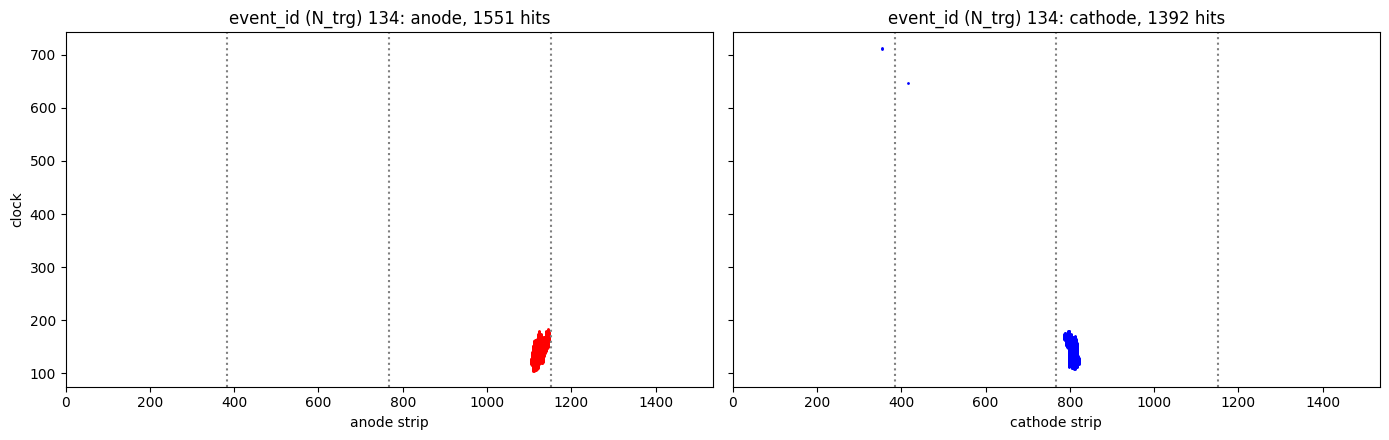

In [5]:
r = ROOT.RDataFrame("RawTreeWriter_sm3/raw", str(OUT_RAW)).AsNumpy(["event_id", "sevt_id", "loopback", "hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock", "anode_time"])
ha, hc = vec(r["hit_a_strip"]), vec(r["hit_c_strip"])
n = np.array([min(len(a), len(c)) for a, c in zip(ha, hc)])
k = int(np.argsort(n)[len(n) - len(n) // 20])   # ヒットの多い方から 5 % くらいのイベント
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, (s, c, name, col) in zip(ax, [(ha[k], vec(r["hit_a_clock"])[k], "anode", "r"), (hc[k], vec(r["hit_c_clock"])[k], "cathode", "b")]):
    a.plot(s, c, ".", ms=2, color=col)
    for p in range(1, 4):
        a.axvline(384 * p, color="gray", ls=":")
    a.set_xlim(0, 1536); a.set_xlabel(f"{name} strip"); a.set_title(f"event_id (N_trg) {r['event_id'][k]}: {name}, {len(s)} hits")
ax[0].set_ylabel("clock")
fig.tight_layout(); plt.show()

## 4. 全イベントの積算

`ReadData/Image_A`, `Image_C` です。パネルごとに分けて描きます(横はパネルの中のストリップ 0〜383)。
クロック 100 前後の横の帯がトリガーの時刻(μ-PIC に一番近いところで電離した電子)で、そこから上へドリフトの長さだけ飛跡が伸びます。
いつも鳴っているストリップ(縦の線)や、ボードが無い所(c01 = カソードのストリップ 128〜255)も見えます。

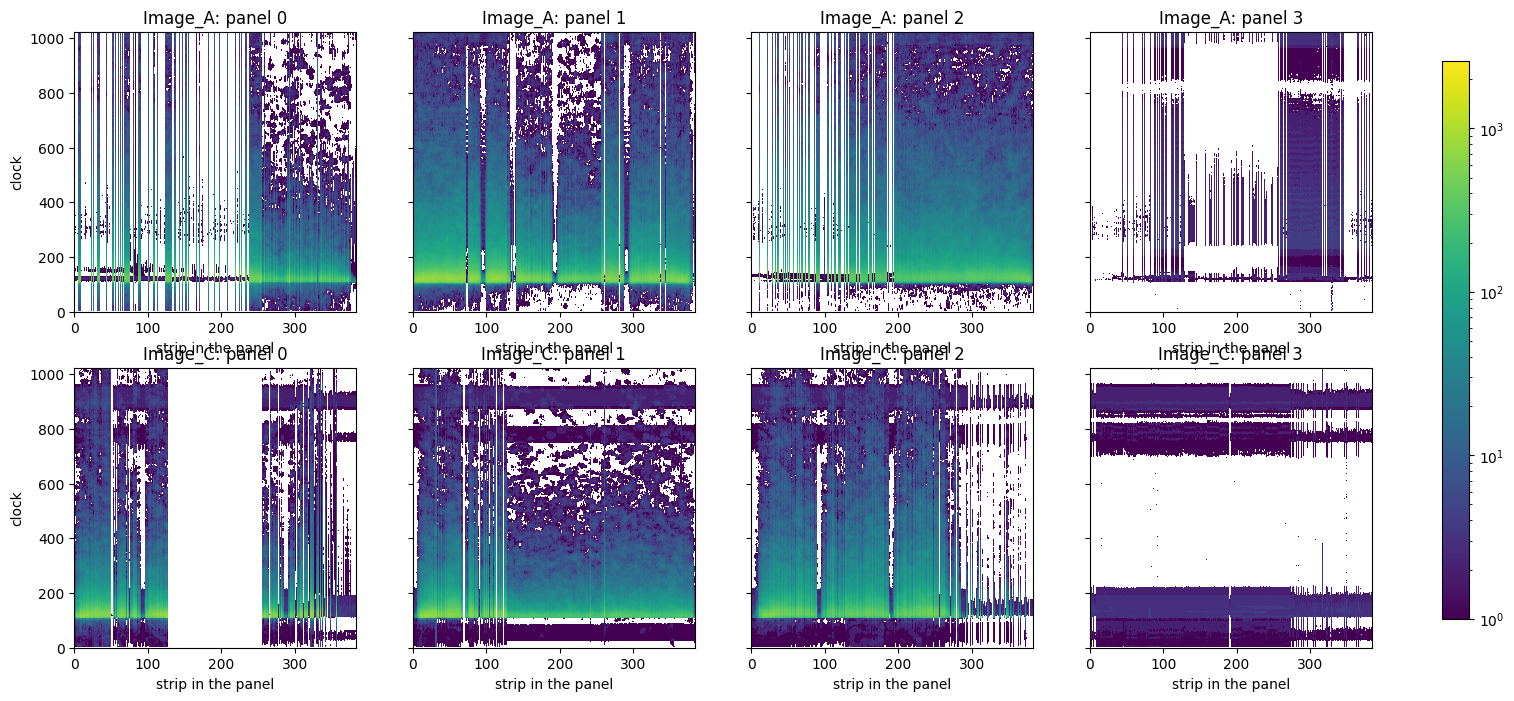

In [6]:
fig, axs = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
imgs = {name: th2(F.Get(f"ReadData/{name}")) for name in ["Image_A", "Image_C"]}
vmax = max(v[0].max() for v in imgs.values())
for row, name in enumerate(["Image_A", "Image_C"]):
    a, ex, ey = imgs[name]
    for p in range(4):
        ax = axs[row, p]
        m = ax.pcolormesh(np.arange(385), ey, a[384 * p:384 * (p + 1)].T, norm=LogNorm(vmin=1, vmax=vmax), shading="flat")
        ax.set_title(f"{name}: panel {p}"); ax.set_xlabel("strip in the panel")
    axs[row, 0].set_ylabel("clock")
fig.colorbar(m, ax=axs, fraction=0.02)
plt.show()

## 5. イベントのそろい方と時刻

`IDcheck_Loopback`(ボードの読み進めが起きた)の数と、`N_time`(1 カウント約 100 µs)から求めたイベントのレートです。

In [7]:
ev = evs_table(str(OUT) + ".log") if Path(str(OUT) + ".log").exists() else {}
print("evs:", {k: v for k, v in ev.items() if k in ("Anode_Data", "Cathode_Data", "IDcheck_Loopback")})
print("loopback in the first 5000 events:", int(r["loopback"].sum()))
t = np.array([v[0] for v in r["anode_time"]], dtype=float)
print(f"event_id {r['event_id'][0]} - {r['event_id'][-1]},  N_time {t[0]:.0f} - {t[-1]:.0f}",
      f"-> {len(t) / ((t[-1] - t[0]) * 1e-4):.0f} events/s (1 count = 100 us)")

evs: {'Anode_Data': 50000, 'Cathode_Data': 50000, 'IDcheck_Loopback': 0}
loopback in the first 5000 events: 0
event_id 1 - 5000,  N_time 1058 - 114863 -> 439 events/s (1 count = 100 us)


## 6. パラメータ

In [8]:
show_params("smile3_tpc_only", "ReadData")

data_dir = "{data_root}/storage_g0/run_20260628T232149Z"
    1 ラン分の生データ(tpc_enc_a<ボード>_<番号>.raw, tpc_enc_c<ボード>_<番号>.raw)のディレクトリ
reverse_TPC = false
    true: エンコーダーのストリップのビットの並びを反転して読む
TPC_Only = true
    true: TPC だけを読む(SMILE-2+ の HA のファイルは探さない)
event_id = true
    イベント ID に使うもの。true: トリガーカウンタ(N_trg)、false: N_gso & 0x1fffffff
Image_A_C = false
    true: 全イベントのヒットを積算した図 Image_A / Image_C(ストリップ × クロック)を保存する
FADC_TH = false
    true: FADC 波形のヒストグラムを作る(PNG を書くパラメータは config/smile3_tpc_only.json を参照)
